<a href="https://colab.research.google.com/github/mohazaki-16/ML-Mohammed-Alali/blob/main/rf_gridsearch_benchmark.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# ARTI 503 Stage 1: Sequential Benchmark
## Random Forest Hyperparameter Search (grid search + cross-validation)

Run the cells from top to bottom. Edit the settings in step 2 only.
**Everyone in the group must use the same settings** so the per-member table is comparable.

**Sequential workload:** nested loops over hyperparameter combinations x CV folds, each iteration fitting a `RandomForestClassifier` with `n_jobs=1`. All iterations are independent, which is what we will parallelise in the next stage.

## 1. Install dependencies (run once)

In [1]:
%pip install numpy scikit-learn matplotlib psutil pandas

## 2. Settings (edit these)

In [2]:
MEMBER = "YourName"        # your name (used in output file names)

# Single benchmark
N_SAMPLES  = 5000
N_FEATURES = 20
GRID       = "medium"      # small (8) | medium (27) | large (48) combinations
CV         = 3             # cross-validation folds
REPEATS    = 5             # timed repeats
WARMUP     = 0             # untimed warm-up runs
SEED       = 42

# Scalability sweep (time vs problem size)
SWEEP_SAMPLES = [1000, 2000, 4000, 8000]
SWEEP_GRID    = "small"
SWEEP_REPEATS = 3

# Profile
PROFILE_TOP = 12           # rows shown per profile table
OUT_DIR     = "results"

## 3. Imports and hyperparameter grids

In [3]:
import cProfile, io, itertools, os, platform, pstats, statistics, subprocess, sys, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.datasets import make_classification
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score
from sklearn.model_selection import StratifiedKFold

GRIDS = {
    "small":  {"n_estimators": [50, 100],          "max_depth": [8, 16],          "min_samples_leaf": [1, 4]},     # 8 combos
    "medium": {"n_estimators": [50, 100, 200],     "max_depth": [8, 16, None],    "min_samples_leaf": [1, 2, 4]},  # 27 combos
    "large":  {"n_estimators": [50, 100, 200, 300],"max_depth": [6, 10, 16, None],"min_samples_leaf": [1, 2, 4]},  # 48 combos
}
os.makedirs(OUT_DIR, exist_ok=True)

## 4. System specification (copy into the report's CPU table)

In [4]:
def cpu_model():
    try:
        if sys.platform.startswith("linux"):
            with open("/proc/cpuinfo") as f:
                for line in f:
                    if line.lower().startswith("model name"):
                        return line.split(":", 1)[1].strip()
        elif sys.platform == "darwin":
            return subprocess.check_output(["sysctl", "-n", "machdep.cpu.brand_string"], text=True).strip()
        elif sys.platform.startswith("win"):
            out = subprocess.check_output(["wmic", "cpu", "get", "name"], text=True, stderr=subprocess.DEVNULL)
            lines = [l.strip() for l in out.splitlines() if l.strip()]
            if len(lines) > 1:
                return lines[1]
    except Exception:
        pass
    return platform.processor() or "unknown"

import sklearn
INFO = {
    "cpu_model": cpu_model(),
    "logical_cores": os.cpu_count(),
    "physical_cores": None,
    "ram_gb": None,
    "os": f"{platform.system()} {platform.release()}",
    "python": platform.python_version(),
    "numpy": np.__version__,
    "scikit_learn": sklearn.__version__,
}
try:
    import psutil
    INFO["physical_cores"] = psutil.cpu_count(logical=False)
    INFO["ram_gb"] = round(psutil.virtual_memory().total / 1024**3, 1)
except ImportError:
    print("Install psutil for physical core count and RAM: pip install psutil")

display(pd.DataFrame(INFO, index=["value"]).T)

,value
cpu_model,Intel(R) Xeon(R) CPU @ 2.20GHz
logical_cores,2
physical_cores,1
ram_gb,12.7
os,Linux 6.6.122+
python,3.13.16
numpy,2.1.3
scikit_learn,1.6.1


## 5. Data and the sequential workload

In [5]:
def make_data(n_samples, n_features, seed):
    X, y = make_classification(
        n_samples=n_samples, n_features=n_features,
        n_informative=max(2, n_features // 2), n_redundant=max(0, n_features // 5),
        n_classes=2, random_state=seed)
    return X, y


def grid_search_sequential(X, y, grid, cv, seed):
    """
    Hand-written SEQUENTIAL grid search with cross-validation.

        for each hyperparameter combination      <- level 1 (grid)
            for each CV fold                     <- level 2 (folds)
                fit RandomForest (n_jobs=1)      <- level 3 (trees, inside sklearn)
                score on validation fold
    Only the final "pick the best mean score" step needs all results.
    """
    keys = list(grid.keys())
    combos = list(itertools.product(*(grid[k] for k in keys)))
    folds = list(StratifiedKFold(n_splits=cv, shuffle=True, random_state=seed).split(X, y))

    fit_time = score_time = 0.0
    results = []
    for combo in combos:
        params = dict(zip(keys, combo))
        fold_scores = []
        for train_idx, val_idx in folds:
            model = RandomForestClassifier(random_state=seed, n_jobs=1, **params)
            t0 = time.perf_counter()
            model.fit(X[train_idx], y[train_idx])
            t1 = time.perf_counter()
            pred = model.predict(X[val_idx])
            fold_scores.append(accuracy_score(y[val_idx], pred))
            t2 = time.perf_counter()
            fit_time += t1 - t0
            score_time += t2 - t1
        results.append((statistics.mean(fold_scores), params))

    best_score, best_params = max(results, key=lambda r: r[0])
    return {"best_score": best_score, "best_params": best_params,
            "n_combos": len(combos), "n_fits": len(combos) * cv,
            "fit_time": fit_time, "score_time": score_time}

## 6. Benchmark helpers

In [6]:
def summarise(values):
    return {"mean": statistics.mean(values),
            "std": statistics.stdev(values) if len(values) > 1 else 0.0,
            "min": min(values), "median": statistics.median(values)}


def run_config(n_samples, n_features, grid_name, cv, repeats, warmup, seed):
    """Time the full grid search `repeats` times and return one summary row."""
    grid = GRIDS[grid_name]
    n_combos = int(np.prod([len(v) for v in grid.values()]))
    print("-" * 70)
    print(f"n_samples={n_samples}  n_features={n_features}  grid={grid_name} ({n_combos} combos)  "
          f"cv={cv}  fits={n_combos * cv}  repeats={repeats}")
    print("-" * 70)

    X, y = make_data(n_samples, n_features, seed)
    for _ in range(warmup):
        grid_search_sequential(X, y, grid, cv, seed)

    totals, fits, scores, last = [], [], [], None
    for r in range(1, repeats + 1):
        t0 = time.perf_counter()
        last = grid_search_sequential(X, y, grid, cv, seed)
        total = time.perf_counter() - t0
        totals.append(total); fits.append(last["fit_time"]); scores.append(last["score_time"])
        print(f"    run {r}/{repeats}: {total:8.3f} s  (fit {last['fit_time']:.3f} s, "
              f"predict+score {last['score_time']:.3f} s)")

    s_total, s_fit = summarise(totals), summarise(fits)
    fit_share = 100 * s_fit["mean"] / s_total["mean"]
    print(f"\n  TOTAL  mean {s_total['mean']:.3f} s | std {s_total['std']:.3f} s | "
          f"min {s_total['min']:.3f} s | median {s_total['median']:.3f} s")
    print(f"  fit() share of total time: {fit_share:.1f} %")
    print(f"  best CV accuracy {last['best_score']:.4f} with {last['best_params']}\n")

    return {"member": MEMBER, "cpu_model": INFO["cpu_model"],
            "physical_cores": INFO["physical_cores"], "logical_cores": INFO["logical_cores"],
            "n_samples": n_samples, "n_features": n_features, "grid": grid_name,
            "n_combos": last["n_combos"], "cv": cv, "n_fits": last["n_fits"], "repeats": repeats,
            "mean_s": round(s_total["mean"], 4), "std_s": round(s_total["std"], 4),
            "min_s": round(s_total["min"], 4), "median_s": round(s_total["median"], 4),
            "fit_share_pct": round(fit_share, 2), "best_cv_accuracy": round(last["best_score"], 4)}


def profile_once(n_samples, n_features, grid_name, cv, seed, top, prof_path):
    """Run one search under cProfile and print the hottest functions."""
    X, y = make_data(n_samples, n_features, seed)
    profiler = cProfile.Profile()
    profiler.enable()
    grid_search_sequential(X, y, GRIDS[grid_name], cv, seed)
    profiler.disable()
    profiler.dump_stats(prof_path)
    for sort_key, title in (("tottime", "own time"), ("cumulative", "cumulative time")):
        buf = io.StringIO()
        pstats.Stats(profiler, stream=buf).strip_dirs().sort_stats(sort_key).print_stats(top)
        text = buf.getvalue()
        print(f"\n--- cProfile: top {top} by {title} ---")
        print(text[text.find("ncalls"):] if "ncalls" in text else text)
    print(f"Profile saved to {prof_path}")

## 7. Single benchmark
Prints timing per run, mean / std / min / median, and the share of time spent in `fit()`.

In [7]:
single_row = run_config(N_SAMPLES, N_FEATURES, GRID, CV, REPEATS, WARMUP, SEED)
single_df = pd.DataFrame([single_row])
single_df.to_csv(os.path.join(OUT_DIR, f"benchmark_{MEMBER}_single.csv"), index=False)
display(single_df)

----------------------------------------------------------------------
n_samples=5000  n_features=20  grid=medium (27 combos)  cv=3  fits=81  repeats=5
----------------------------------------------------------------------
    run 1/5:  181.281 s  (fit 178.491 s, predict+score 2.753 s)
    run 2/5:  165.724 s  (fit 163.064 s, predict+score 2.625 s)
    run 3/5:  164.871 s  (fit 162.345 s, predict+score 2.489 s)
    run 4/5:  170.089 s  (fit 167.399 s, predict+score 2.652 s)
    run 5/5:  164.133 s  (fit 161.621 s, predict+score 2.477 s)

  TOTAL  mean 169.220 s | std 7.128 s | min 164.133 s | median 165.724 s
  fit() share of total time: 98.4 %
  best CV accuracy 0.9472 with {'n_estimators': 100, 'max_depth': None, 'min_samples_leaf': 1}



,member,cpu_model,physical_cores,logical_cores,n_samples,n_features,grid,n_combos,cv,n_fits,repeats,mean_s,std_s,min_s,median_s,fit_share_pct,best_cv_accuracy
0,YourName,Intel(R) Xeon(R) CPU @ 2.20GHz,1,2,5000,20,medium,27,3,81,5,169.2198,7.1281,164.133,165.7243,98.44,0.9472


## 8. Profile (most time-consuming parts)

In [8]:
profile_once(N_SAMPLES, N_FEATURES, GRID, CV, SEED, PROFILE_TOP, os.path.join(OUT_DIR, "profile.prof"))


--- cProfile: top 12 by own time ---
ncalls  tottime  percall  cumtime  percall filename:lineno(function)
     9450  141.346    0.015  158.954    0.017 _classes.py:231(_fit)
    28432    3.493    0.000    7.196    0.000 validation.py:1490(check_random_state)
    18982    3.073    0.000    3.178    0.000 _ufunc_config.py:465(inner)
    47898    2.225    0.000    3.818    0.000 _tags.py:303(_find_tags_provider)
    47412    1.845    0.000    6.330    0.000 inspect.py:2403(_signature_from_function)
     9450    1.647    0.000    2.816    0.000 _classes.py:1032(predict_proba)
   663444    1.464    0.000    2.722    0.000 inspect.py:2775(__init__)
      183    1.177    0.006    1.430    0.008 {built-in method time.sleep}
    47331    1.040    0.000    8.692    0.000 base.py:200(_get_param_names)
    19553    1.033    0.000    2.125    0.000 _arraysetops_impl.py:344(_unique1d)
     9450    1.014    0.000  167.101    0.018 _forest.py:151(_parallel_build_trees)
     9694    0.804    0.000    

## 9. Scalability sweep (time vs problem size)

----------------------------------------------------------------------
n_samples=1000  n_features=20  grid=small (8 combos)  cv=3  fits=24  repeats=3
----------------------------------------------------------------------
    run 1/3:    8.564 s  (fit 8.279 s, predict+score 0.274 s)
    run 2/3:    8.512 s  (fit 8.242 s, predict+score 0.261 s)
    run 3/3:    7.610 s  (fit 7.349 s, predict+score 0.252 s)

  TOTAL  mean 8.229 s | std 0.536 s | min 7.610 s | median 8.512 s
  fit() share of total time: 96.7 %
  best CV accuracy 0.9200 with {'n_estimators': 100, 'max_depth': 16, 'min_samples_leaf': 1}

----------------------------------------------------------------------
n_samples=2000  n_features=20  grid=small (8 combos)  cv=3  fits=24  repeats=3
----------------------------------------------------------------------
    run 1/3:   13.792 s  (fit 13.456 s, predict+score 0.327 s)
    run 2/3:   13.134 s  (fit 12.816 s, predict+score 0.309 s)
    run 3/3:   13.214 s  (fit 12.902 s, predict+

,n_samples,n_fits,mean_s,std_s,min_s,median_s,fit_share_pct
0,1000,24,8.2290,0.5363,7.6104,8.5120,96.69
1,2000,24,13.3802,0.3590,13.1343,13.2141,97.59
2,4000,24,24.5706,0.1255,24.4382,24.5855,98.19
3,8000,24,49.3520,0.4902,48.8055,49.4975,98.58


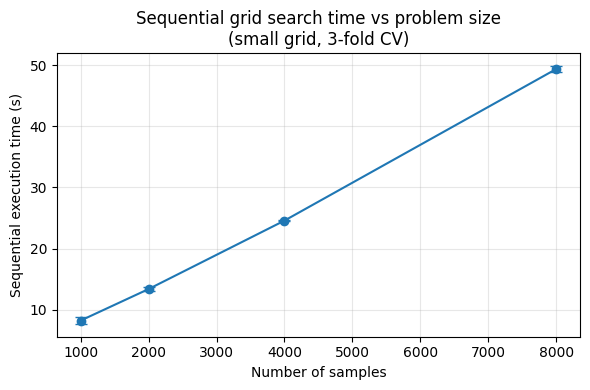

In [9]:
sweep_rows = [run_config(n, N_FEATURES, SWEEP_GRID, CV, SWEEP_REPEATS, WARMUP, SEED) for n in SWEEP_SAMPLES]
sweep_df = pd.DataFrame(sweep_rows)
sweep_df.to_csv(os.path.join(OUT_DIR, f"benchmark_{MEMBER}_sweep.csv"), index=False)
display(sweep_df[["n_samples", "n_fits", "mean_s", "std_s", "min_s", "median_s", "fit_share_pct"]])

plt.figure(figsize=(6, 4))
plt.errorbar(sweep_df["n_samples"], sweep_df["mean_s"], yerr=sweep_df["std_s"], marker="o", capsize=4)
plt.xlabel("Number of samples")
plt.ylabel("Sequential execution time (s)")
plt.title(f"Sequential grid search time vs problem size\n({SWEEP_GRID} grid, {CV}-fold CV)")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, f"scaling_{MEMBER}_sweep.png"), dpi=150)
plt.show()

## 10. Copy these into the report
- CPU specification (step 4): one row per member
- Mean / std / min (step 7): per-member timing table
- Profile tables (step 8): most time-consuming parts
- Figure and table (step 9): scalability with problem size

All CSVs and the plot are saved in the `results/` folder.